GroupBy

In [1]:
import pandas as pd

In [26]:
data = { 
'Gender': ['m', 'f', 'f', 'm', 'f', 'm', 'm'], 
'Height': [172, 171, 169, 173, 170, 175, 178] 
} 
df = pd.DataFrame(data) 
df

,Gender,Height
0,m,172
1,f,171
2,f,169
3,m,173
4,f,170
5,m,175
6,m,178


In [3]:
#Splitting the data into separate groups
f_filter = df['Gender']=='f' 
print(df[f_filter]) 
m_filter = df['Gender']=='m' 
print(df[m_filter]) 

  Gender  Height
1      f     171
2      f     169
4      f     170
  Gender  Height
0      m     172
3      m     173
5      m     175
6      m     178


In [4]:
f_avg = df[f_filter]['Height'].mean() 
m_avg = df[m_filter]['Height'].mean() 
print(f_avg,m_avg) 

170.0 174.5


In [5]:
df_output=pd.DataFrame({'Gender':['f','m'],'Height': 
[f_avg,m_avg]}) 
print(df_output)

  Gender  Height
0      f   170.0
1      m   174.5


In [27]:
print(df.groupby('Gender')['Height'].mean())

Gender
f    170.0
m    174.5
Name: Height, dtype: float64


In [28]:
df1=df.groupby('Gender')['Height'].mean().reset_index()

C:\Users\Gokul\AppData\Local\Temp\ipykernel_7128\1594032910.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Gender',y='Height',data=df1,palette='husl')


<Axes: xlabel='Gender', ylabel='Height'>

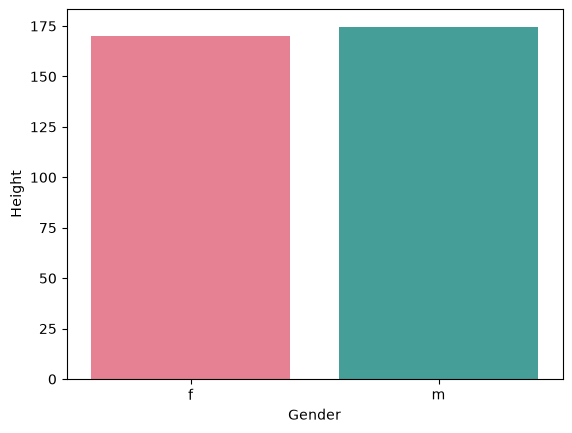

In [29]:
import seaborn as sns 
sns.barplot(x='Gender',y='Height',data=df1,palette='husl')

In [8]:
ipl_data = {'Team': ['Riders', 'Riders', 'Devils', 'Devils', 'Kings', 
'kings', 'Kings', 'Kings', 'Riders', 'Royals', 'Royals', 'Riders'], 
'Rank': [1,2,2,3,3,4,1,1,2,4,1,2], 
'Year': 
[2014,2015,2014,2015,2014,2015,2016,2017,2016,2014,2015,2017], 
'Points':[876,789,863,673,741,812,756,788,694,701,804,690]} 
df = pd.DataFrame(ipl_data) 
df

,Team,Rank,Year,Points
0,Riders,1,2014,876
1,Riders,2,2015,789
2,Devils,2,2014,863
3,Devils,3,2015,673
4,Kings,3,2014,741
5,kings,4,2015,812
6,Kings,1,2016,756
7,Kings,1,2017,788
8,Riders,2,2016,694
9,Royals,4,2014,701


Split Data into Groups

In [11]:
print(df.groupby('Team'))

View Groups

In [12]:
print(df.groupby('Team').groups)

{'Devils': [2, 3], 'Kings': [4, 6, 7], 'Riders': [0, 1, 8, 11], 'Royals': [9, 10], 'kings': [5]}


Group by with multiple columns

In [13]:
print(df.groupby(['Team','Year']).groups) 

{('Devils', 2014): RangeIndex(start=2, stop=3, step=1), ('Devils', 2015): RangeIndex(start=3, stop=4, step=1), ('Kings', 2014): RangeIndex(start=4, stop=5, step=1), ('Kings', 2016): RangeIndex(start=6, stop=7, step=1), ('Kings', 2017): RangeIndex(start=7, stop=8, step=1), ('Riders', 2014): RangeIndex(start=0, stop=1, step=1), ('Riders', 2015): RangeIndex(start=1, stop=2, step=1), ('Riders', 2016): RangeIndex(start=8, stop=9, step=1), ('Riders', 2017): RangeIndex(start=11, stop=12, step=1), ('Royals', 2014): RangeIndex(start=9, stop=10, step=1), ('Royals', 2015): RangeIndex(start=10, stop=11, step=1), ('kings', 2015): RangeIndex(start=5, stop=6, step=1)}


Iterating through Groups

In [14]:
grouped = df.groupby('Year')
for year,group in grouped: 
    print(year) 
    print(group)

2014
     Team  Rank  Year  Points
0  Riders     1  2014     876
2  Devils     2  2014     863
4   Kings     3  2014     741
9  Royals     4  2014     701
2015
      Team  Rank  Year  Points
1   Riders     2  2015     789
3   Devils     3  2015     673
5    kings     4  2015     812
10  Royals     1  2015     804
2016
     Team  Rank  Year  Points
6   Kings     1  2016     756
8  Riders     2  2016     694
2017
      Team  Rank  Year  Points
7    Kings     1  2017     788
11  Riders     2  2017     690


Select a Group 

In [15]:
print(grouped.get_group(2014)) 

     Team  Rank  Year  Points
0  Riders     1  2014     876
2  Devils     2  2014     863
4   Kings     3  2014     741
9  Royals     4  2014     701


Aggregations 

In [17]:
import numpy as np

In [18]:
grouped = df.groupby('Year') 
print(grouped['Points'].agg(np.mean)) 

Year
2014    795.25
2015    769.50
2016    725.00
2017    739.00
Name: Points, dtype: float64


In [19]:
grouped = df.groupby('Team') 
print(grouped['Points'].agg([np.sum, np.mean, np.std])) 

         sum        mean        std
Team                               
Devils  1536  768.000000  95.000000
Kings   2285  761.666667  19.601587
Riders  3049  762.250000  76.701939
Royals  1505  752.500000  51.500000
kings    812  812.000000   0.000000


Named aggregations 

In [20]:
df.groupby("Team").agg(
avg_Points = ("Points", "mean"),
max_Points = ("Points", "max")
)

,avg_Points,max_Points
Team,,
Devils,768.000000,863
Kings,761.666667,788
Riders,762.250000,876
Royals,752.500000,804
kings,812.000000,812


Sorting the results

In [21]:
df1=df.groupby("Team", as_index=False).agg(
avg_points = ("Points", "mean")
).sort_values(by="avg_points", ascending=False).head() 
print(df1) 

     Team  avg_points
4   kings  812.000000
0  Devils  768.000000
2  Riders  762.250000
1   Kings  761.666667
3  Royals  752.500000


Plot the results  

In [22]:
import seaborn as sns  
import matplotlib.pyplot as plt 


C:\Users\Gokul\AppData\Local\Temp\ipykernel_7128\704281244.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Team',y='avg_points',data=df1,palette='husl')


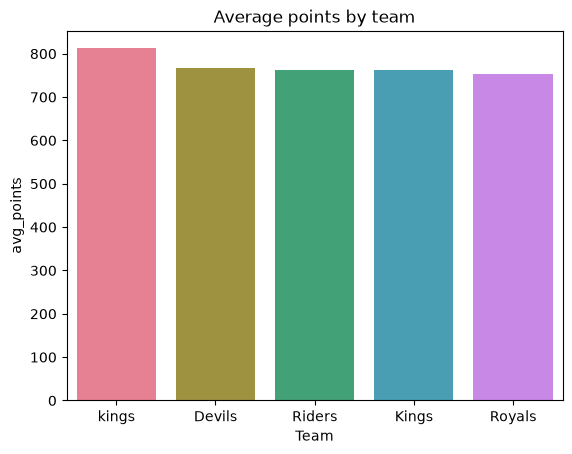

In [23]:
sns.barplot(x='Team',y='avg_points',data=df1,palette='husl') 
plt.title('Average points by team') 
plt.show()

Identify the unique values in column

In [24]:
df1=df.groupby("Team", as_index=False).agg(
unique_values = ("Year","unique") 
) 
print(df1)

     Team             unique_values
0  Devils              [2014, 2015]
1   Kings        [2014, 2016, 2017]
2  Riders  [2014, 2015, 2016, 2017]
3  Royals              [2014, 2015]
4   kings                    [2015]


Number of unique values

In [25]:
df1=df.groupby("Team", as_index=False).agg(
number_of_unique_values = ("Year","nunique")
) 
print(df1)

     Team  number_of_unique_values
0  Devils                        2
1   Kings                        3
2  Riders                        4
3  Royals                        2
4   kings                        1
